##### Master Degree in Computer Science and Data Science for Economics and Health

# Encoder, decoder and cross-attention

### Prof. Alfio Ferrara

## Introduction

In L1.0 and L1.1 we built a network that reads **one** text. Every word of the text is a position, each position reads the positions on its left, and at the end the vector of a position is used to predict a word: the next word of the same text (L1.1), or the answer at the end of a list (L1.0). The model, in the form of L1.1, is

$$
x^{(0)}_t = E[w_t] + P[t], \qquad x \leftarrow x + \mathrm{Attn}(\mathrm{LN}(x)), \qquad x \leftarrow x + \mathrm{MLP}(\mathrm{LN}(x)), \qquad \text{scores}_t = \mathrm{LN}(x_t)\, W_U + b,
$$

where the two updates are repeated in each block. Many problems have **two** texts instead of one: a text that is given (the *source*) and a text that must be written (the *target*). Translation is the standard case; a question and its answer, a long text and its summary, an instruction and its execution are others. The Transformer of Vaswani et al. (2017) was designed for translation, and its form is the one that gives this notebook its title: an **encoder**, that reads the source, and a **decoder**, that writes the target one word at a time while looking at what the encoder has read. The piece that joins the two is **cross-attention**.

We do not need any new ingredient: the blocks are those of L1.1. What changes is the **mask**, that is, which positions are allowed to read which, and **where the keys and the values come from**. The notebook follows this order:

1. **Step 1**: the task. Our toy world is written in two languages, A and B, and we want a network that translates from A to B;
2. **Step 2**: the theory. One attention function with a mask, used in three ways (encoder, decoder, cross-attention), and the two blocks that result;
3. **Step 3**: we train the network. The first result is a lesson on what the network learns when the world of the data is always the same;
4. **Step 4**: we look inside the cross-attention, to see whether it does what the theory says;
5. **Step 5**: *teacher forcing* and decoding. The network is trained with the true target as input and is used with its own words: do the two situations differ?

As in the previous notebooks, the toy world has its advantages (we can read everything, and train in a few seconds) and its limits (no ambiguity, no phenomenon that appears only at large scale): we say at each step what changes with the real models. We use few seeds (three or two) and we say it every time: the numbers are an indication, not a measure.

In [1]:
import time
import inspect
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

from nlp import toyworld, tinylm

warnings.filterwarnings("ignore", category=FutureWarning)

## Step 1: the task, two languages for the same world

> **A simple example.** In our world `anna` lives in `milan`. In language A we write `anna lives in milan .`; in language B, a language with other words and another order, the same fact is written `anna zuszu baris .`. The name is copied, `lives in` has become `zuszu` (the `in` has disappeared), and `milan` has become `baris`. Other facts change the order: `anna likes red .` becomes `lisval duzul anna .`, where the colour comes first and the name last. To write a sentence of B, then, it is not enough to replace each word of A with a word of B: the network must **find** in the source the words that it needs, in an order that is not the one of the source.
>
> The question of this section is: how do we ask a network to **read a text and write another one**? The intuition is to use two networks, one that reads the source and one that writes the target, and to let the second one consult what the first has read.

In [2]:
world = toyworld.ToyWorld(toyworld.WorldConfig(n_people=12, seed=0))
LANGUAGE_B = world.language["B"]
vocab_a, vocab_b = world.vocabulary(("A",)), world.vocabulary(("B",))
print(f"language A: {len(vocab_a)} words, language B: {len(vocab_b)} words (names and `.` are common to both)\n")
for source, target in world.translation(3, 2):
    print("A:", " ".join(source))
    print("B:", " ".join(target), "\n")

language A: 53 words, language B: 51 words (names and `.` are common to both)

A: <s> diego drinks coffee . diego likes yellow . he is a nurse . marco drinks coffee . he lives in naples . marco likes brown . </s>
B: <s> diego torge dinsos . kungos duzul diego . rerfur pumus vudas . marco torge dinsos . pumus zuszu tunrus . kesva duzul marco . </s> 

A: <s> mario is a clerk . he drinks water . he likes yellow . marta is a mechanic . she drinks tea . she likes brown . </s>
B: <s> bilpel mario vudas . pumus lurbos dinsos . kungos duzul pumus . vaszan marta vudas . lirnes datol dinsos . kesva duzul lirnes . </s> 



A document is made of facts about two people, three facts for each, one sentence per fact; when two consecutive sentences are about the same person, the second can use a pronoun (`she`, `he`), that language B writes with its own word. The two documents of each pair say the same facts, in the same order. The way in which a fact is written in B depends on the **relation**: the table shows the facts of `anna`, with the name and with the pronoun.

In [3]:
rows = []
for relation in toyworld.RELATIONS:
    fact = ("anna", relation, world.attributes["anna"][relation])
    rows.append({"relation": relation,
                 "A": " ".join(world.say(fact, "A")), "B": " ".join(world.say(fact, "B")),
                 "A with pronoun": " ".join(world.say(fact, "A", pronoun=True)), "B with pronoun": " ".join(world.say(fact, "B", pronoun=True))})
pd.DataFrame(rows).set_index("relation")

,A,B,A with pronoun,B with pronoun
relation,,,,
drink,anna drinks cocoa .,anna tavar dinsos .,she drinks cocoa .,lirnes tavar dinsos .
job,anna is a farmer .,parpol anna vudas .,she is a farmer .,parpol lirnes vudas .
city,anna lives in milan .,anna zuszu baris .,she lives in milan .,lirnes zuszu baris .
color,anna likes red .,lisval duzul anna .,she likes red .,lisval duzul lirnes .


Language B has four templates, one for each relation, with the value, the subject and a word for the relation in a different order each time (the table above shows it): the first word of a sentence of B is the name for `drinks` and `lives`, but it is the value for `is` and `likes`. The words `in` and `a` of A have no counterpart. Before using a network, a reference: the translation **word by word**, that replaces each word of A with its word of B (names and `.` are copied) and keeps the order of A. It is the best that we can do without reading the sentence as a whole.

In [4]:
a2b = dict(LANGUAGE_B["lexicon"])
a2b.update({person: person for person in world.people})
a2b.update({".": ".", "<s>": "<s>", "</s>": "</s>"})
for relation in toyworld.RELATIONS:
    a2b[toyworld.LANGUAGE_A["question_word"][relation]] = LANGUAGE_B["question_word"][relation]

def word_by_word(source):
    return [a2b[word] for word in source if word in a2b]            # `in` and `a` have no counterpart

pairs = world.translation(11, 1000)
exact = np.mean([word_by_word(source) == target for source, target in pairs])
same_place = np.mean([np.mean([x == y for x, y in zip(word_by_word(source), target)]) for source, target in pairs])
print(f"word by word: {exact:.1%} of the sentences are exact, {same_place:.1%} of the words are the right ones in the right place")

word by word: 0.0% of the sentences are exact, 59.7% of the words are the right ones in the right place


The dictionary translates the words well but not the sentences: no document is exact, and only 59.7% of the words are the right ones in the right place. The reason is the one that the table shows: each relation has its own order in language B, and `in` and `a` of A have no counterpart, so that the words of A that follow them move by one or two places. To translate, the network has to decide the order of each sentence of B from the relation that the sentence of A says, and to take each value from the right place of the source.

## Step 2: one attention, three uses

The theory of this step is short, because there is no new ingredient: it is a different way of **using** the attention of L1.0. We first write the attention in a form that contains all the cases, then we look at the three uses one at a time, and finally at the two blocks that come out.

### One function, with a mask

> **A simple example.** Take the source `<s> anna lives in milan . </s>` and the target `<s> anna zuszu baris . </s>`. Each word of the source, of the target, can look at some of the words of the source and of the target. We can write it in a table with one row for each word that looks and one column for each word that is looked at, with a 1 where looking is allowed: three tables, one for the words of the source that look at the source, one for those of the target that look at the target, one for those of the target that look at the source.
>
> The question of this section is: can the three tables be the same piece of code? The intuition is that the only thing that changes is **who looks** (the queries), **who is looked at** (keys and values) and **the table of allowed pairs**.

In L1.0 the attention took a sequence $X$ and computed, for each position, weights over the positions of the **same** sequence, with a triangular mask. We now let the positions that look (the queries) and the positions that are looked at (the keys and the values) be two different sequences, $X$ and $M$ (for *memory*), and we write the mask as a matrix $A$ with one row for each position of $X$ and one column for each position of $M$, where $A_{ij} = 1$ if the position $i$ of $X$ may read the position $j$ of $M$ and $0$ otherwise:

$$
\mathrm{Attn}(X, M, A) = \mathrm{softmax}\!\left(\frac{(X W_Q)(M W_K)^\top}{\sqrt{d_h}} + \log A\right) (M W_V)\, W_O, \qquad \log 1 = 0,\ \log 0 = -\infty,
$$

for each head (and the heads are then concatenated as in L1.1). Where $A_{ij} = 0$ the score is $-\infty$ and the weight is exactly zero. The attention of L1.0 and L1.1 is the case $M = X$ and $A$ **lower triangular**. There are three cases of interest:

| use | queries $X$ | keys and values $M$ | mask $A$ |
|---|---|---|---|
| self-attention of the **encoder** | the source | the source | all ones (but for the padding) |
| self-attention of the **decoder** | the target | the target | triangular, as in L1.0 |
| **cross-attention** | the target | the output of the encoder | all ones (but for the padding), rectangular |

The code of `tinylm.MultiHeadAttention` has exactly this form: it takes `x`, `memory` and `allowed`, and nothing else distinguishes the three uses. The figure draws the three masks for the pair of the example.

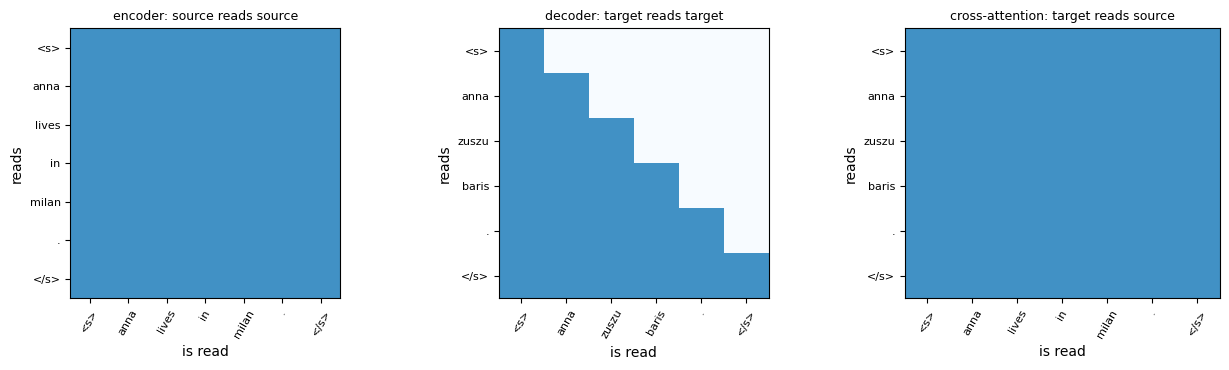

In [5]:
source_words = "<s> anna lives in milan . </s>".split()
target_words = "<s> anna zuszu baris . </s>".split()
n_s, n_t = len(source_words), len(target_words)
masks = {"encoder: source reads source": np.ones((n_s, n_s)),
         "decoder: target reads target": np.tril(np.ones((n_t, n_t))),
         "cross-attention: target reads source": np.ones((n_t, n_s))}
labels = {"encoder: source reads source": (source_words, source_words), "decoder: target reads target": (target_words, target_words),
          "cross-attention: target reads source": (target_words, source_words)}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (title, mask) in zip(axes, masks.items()):
    ax.imshow(mask, cmap="Blues", vmin=0, vmax=1.6)
    rows_, cols_ = labels[title]
    ax.set_xticks(range(len(cols_)), cols_, rotation=60, fontsize=8)
    ax.set_yticks(range(len(rows_)), rows_, fontsize=8)
    ax.set_title(title, fontsize=9)
    ax.set_xlabel("is read"); ax.set_ylabel("reads")
plt.tight_layout()
plt.show()

The decoder is the only one with a triangular mask, and the reason is the same as in L1.0: during training we give the network the whole target at once, and the position that has to predict the word after `anna` must not be able to read `zuszu`, that is its answer. The encoder and the cross-attention do not hide anything: when the decoder starts to write, the source is complete and nothing in it is an answer to hide. The only positions that nobody reads are the **padding**: documents have different lengths, we complete them with `<pad>` to put them in a rectangle, and the mask has a 0 in the columns of the padding (this is why $A$ is not exactly all ones in the table).

Here is the same module used in the three ways, on the example above. The weights are drawn from the module on random vectors, only to show the shapes and the zeros.

In [6]:
torch.manual_seed(0)
attention = tinylm.MultiHeadAttention(d=16, heads=2)
x_source, x_target = torch.randn(1, n_s, 16), torch.randn(1, n_t, 16)
allowed = {"encoder": (x_source, x_source, torch.ones(n_s, n_s, dtype=torch.bool)),
           "decoder": (x_target, x_target, torch.tril(torch.ones(n_t, n_t, dtype=torch.bool))),
           "cross-attention": (x_target, x_source, torch.ones(n_t, n_s, dtype=torch.bool))}
for use, (x, memory, mask) in allowed.items():
    out = attention(x, memory, mask, keep_weights=True)
    print(f"{use:16s} queries {tuple(x.shape)}, memory {tuple(memory.shape)}, mask {tuple(mask.shape)} -> output {tuple(out.shape)},"
          f" weights {tuple(attention.weights.shape)}, weights that are exactly 0: {(attention.weights == 0).float().mean():.0%}")

encoder          queries (1, 7, 16), memory (1, 7, 16), mask (7, 7) -> output (1, 7, 16), weights (1, 2, 7, 7), weights that are exactly 0: 0%
decoder          queries (1, 6, 16), memory (1, 6, 16), mask (6, 6) -> output (1, 6, 16), weights (1, 2, 6, 6), weights that are exactly 0: 42%
cross-attention  queries (1, 6, 16), memory (1, 7, 16), mask (6, 7) -> output (1, 6, 16), weights (1, 2, 6, 7), weights that are exactly 0: 0%


The output has the shape of the **queries**: one vector for each position that looks, whatever the length of the memory. This is what we need: the decoder has one position for each word of B, and each one gets a vector made of what it has read in the source.

### The encoder

> **A simple example.** In `anna lives in milan .` the word `in` does not tell much by itself, and the word `lives` does not say where. But the same sentence, read as a whole, says that the second and third words introduce a city and that the fourth is the city. An encoder is a stack of blocks that gives to **each word of the source a vector that knows the other words of the source**: the vector of `milan` knows that it is the city of `anna`, and the one of `lives` knows that a city follows.
>
> The question of this section is: what does the encoder compute? The intuition is that it works as the layers of L1.1 on the source, with one difference: nothing is hidden, because the source is completely given.

The encoder starts from the embeddings of the words of the source and of their positions, $H^{(0)} = E_s[s_i] + P_s[i]$, and applies blocks in which the self-attention has the mask of the first row of the table (every position reads all the others) followed by the MLP, both with the residual stream and the layer normalization of L1.1:

$$
H \leftarrow H + \mathrm{Attn}\big(\mathrm{LN}(H),\, \mathrm{LN}(H),\, A_{\text{source}}\big), \qquad H \leftarrow H + \mathrm{MLP}\big(\mathrm{LN}(H)\big).
$$

After the last block a final layer normalization gives the **memory** $M$: one vector for each word of the source, that is the only thing that the decoder will know of the source. The encoder is run **once** for each source, whatever the number of words that the decoder writes. Note the difference with L1.1, where the mask was always triangular: here every position of the source can read the positions on its right too. We use the encoder in this way in this notebook; in the notebook on BERT (L1.3) this *bidirectional* reading becomes the main subject.

### The decoder

> **A simple example.** To write `anna zuszu baris .` the decoder writes one word at a time. After `<s>` it writes `anna`; after `<s> anna` it writes `zuszu`; after `<s> anna zuszu` it writes `baris`. When it decides the word after `anna`, `zuszu` and `baris` do not exist yet. During training they exist, because they are in the data, and the network must not use them.
>
> The question of this section is: how do we train the decoder on a whole target at once without letting it copy the answer? The intuition is the one of L1.0: a mask that hides, to each position, the positions that follow.

The decoder is the model of L1.1 with a second reading. Its input is the target **shifted by one**: the positions read $\langle s\rangle, y_1, \dots, y_m$ and must predict $y_1, \dots, y_m, \langle/s\rangle$. The first sub-layer of each block is the causal self-attention of L1.1 (mask $A_{\text{causal}}$); the second is the cross-attention, described below; the third is the MLP. The output layer is the one of L1.1, on the vocabulary of the **target** language. The loss is the cross-entropy of the word that follows, summed over all the positions of the target (the padding is ignored): we train the whole target in one pass, as we trained the whole text in L1.1.

### Cross-attention

> **A simple example.** The decoder has written `anna zuszu` and must write the city. `zuszu` says that the sentence is about a city, but not which: the city is in the source, in the fourth word of `anna lives in milan .`. The decoder needs to ask the source *which word is the city of this sentence?*, receive `milan`, and write `baris`. The sentence of the source that it must read changes with the target sentence that it is writing: for the second sentence of the document it must read another part of the source.
>
> The question of this section is: how can the decoder ask a question to a text that is not its own? The intuition is the dictionary of L1.0: the queries come from the decoder, the keys and the values from the encoder.

In the cross-attention the **query** is computed from the vector of the decoder (*what am I looking for, now that I have written this?*), while the **keys** and the **values** are computed from the memory $M$ (*what does each word of the source say about itself, and what can it give?*). The weights form a matrix with one row for each word of the target and one column for each word of the source: it is the $T_{\text{target}} \times T_{\text{source}}$ matrix of the third panel of the figure, and the row of a position says where the decoder looks in the source in order to write the next word. In the translation models of the years before the Transformer (Bahdanau et al., 2015) the same matrix was already used, and it was called *alignment*. In Step 4 we read it in our network.

### The two blocks

> **A simple example.** In the position that has to write `baris`, three things must happen, in this order. The position must know what has been written (`anna zuszu`), so that it knows that a city is missing. Then it must find `milan` in the source. Finally it must turn the pair *(a city is needed; the source says `milan`)* into the word of B. The question is how to arrange the three operations in a block. The intuition is one sub-layer for each, and each writes its own note in the residual stream, as in L1.1.

The decoder block has therefore three sub-layers, each one with its normalization and its residual connection:

$$
Y \leftarrow Y + \mathrm{Attn}\big(\mathrm{LN}(Y), \mathrm{LN}(Y), A_{\text{causal}}\big), \qquad
Y \leftarrow Y + \mathrm{Attn}\big(\mathrm{LN}(Y),\, M,\, A_{\text{source}}\big), \qquad
Y \leftarrow Y + \mathrm{MLP}\big(\mathrm{LN}(Y)\big),
$$

where $Y$ is the residual stream of the decoder and $M$ is the memory of the encoder, the same in all the blocks of the decoder (every block of the decoder has its own cross-attention matrices, but all read the **final** output of the encoder). The residual stream of Step 1 of L1.1 is still there: the cross-attention writes in it, like the others, a note made of what it has read in the source. The code of the block is in `tinylm.DecoderBlock`.

In [7]:
print(inspect.getsource(tinylm.DecoderBlock.forward))

    def forward(self, x, memory, causal, source_allowed, keep_weights=False):
        h = self.ln1(x)
        x = x + self.self_attention(h, h, causal, keep_weights)
        if self.cross_attention is not None:
            x = x + self.cross_attention(self.ln2(x), memory, source_allowed, keep_weights)
        return x + self.mlp(self.ln3(x))



## Step 3: the network learns to translate

> **A simple example.** In our world `anna` lives in `milan`, and in a collection of documents of this world every sentence about the city of `anna` says `anna lives in milan .`. A network that sees it written thousands of times could learn two different things. It could learn to **read** the source: *the word after `in` is the city, it goes into the target as `baris`*. Or it could learn the **world**: *`anna` lives in `milan`*, and write `baris` after `anna zuszu` without looking at the source. In the documents of this world the two behaviours give the same answers.
>
> The question of this section is: what does the network learn, and how can we tell? The intuition is to give it a source in which `anna` lives somewhere else, and see what it writes.

We build the data. The pairs of documents are generated from a world, as in L1.0 and L1.1; here we need two things that the earlier notebooks did not need: **several worlds** with the same people and the same language B but different facts (the generator takes a seed for the facts of the world and a language B that can be shared), and a **new world** for the test. The first training set has 20,000 pairs, all from our world (seed 0). The tests have 1,000 new pairs from the same world (*known world*) and 1,000 pairs from a world with other facts (*new world*, seed 50). The network is the one of Step 2 with two blocks in the encoder and two in the decoder, two heads, $d = 32$, trained for 1,500 steps with batches of 64 pairs, as in L1.1 (AdamW, learning rate 3e-3, one-cycle schedule).

In [8]:
def tensors(w, seed, n):
    pairs = w.translation(seed, n)
    return torch.tensor(vocab_a.batch([a for a, b in pairs])), torch.tensor(vocab_b.batch([b for a, b in pairs]))

def worlds_dataset(n_worlds, size=20000):
    # `size` pairs from n_worlds worlds (seeds 0, 1, ..., our world is the first), all with the language B of our world
    parts = [tensors(toyworld.ToyWorld(toyworld.WorldConfig(n_people=12, seed=k), language_b=LANGUAGE_B), 100 + k, size // n_worlds)
             for k in range(n_worlds)]
    pad = lambda x, width: F.pad(x, (0, width - x.shape[1]))
    widths = [max(part[i].shape[1] for part in parts) for i in (0, 1)]
    return tuple(torch.cat([pad(part[i], widths[i]) for part in parts]) for i in (0, 1))

new_world = toyworld.ToyWorld(toyworld.WorldConfig(n_people=12, seed=50), language_b=LANGUAGE_B)
TEST = {"known world": tensors(world, 11, 1000), "new world": tensors(new_world, 12, 1000)}
same_facts = sum(world.attributes[p][r] == new_world.attributes[p][r] for p in world.people for r in toyworld.RELATIONS)
print(f"the new world has the same value as ours in {same_facts} of the {len(world.people) * 4} facts (by chance we expect about {len(world.people) * 4 / 6:.0f})")

single = worlds_dataset(1)
print("training set:", tuple(single[0].shape), "source,", tuple(single[1].shape), "target; the longest source has", single[0].shape[1], "positions")

the new world has the same value as ours in 2 of the 48 facts (by chance we expect about 8)


training set: (20000, 30) source, (20000, 26) target; the longest source has 30 positions


Before training, the size of the network and its parts: the two languages have their own embeddings (the source and the target are two vocabularies), the encoder has its blocks, the decoder has its blocks with the cross-attention.

In [9]:
trained = {}

def train_translation(name, data, seeds, steps=1500, **kwargs):
    for seed in seeds:
        start = time.time()
        model = tinylm.fit_translation(*data, seed=seed, steps=steps, **kwargs)
        trained[name, seed] = model
        print(f"{name}, seed {seed}: {model.n_parameters():,} parameters, final loss {model.loss_curve[-1]:.3f}, {time.time() - start:.0f} s")

def results(name, seeds):
    rows = {}
    for seed in seeds:
        model = trained[name, seed]
        row = {}
        for test, (source, target) in TEST.items():
            exact, words = tinylm.translation_accuracy(model, source, target)
            row[f"{test}: sentences"], row[f"{test}: words"] = exact, words
        rows[f"seed {seed}"] = row
    return pd.DataFrame(rows).T.round(3)

train_translation("one world", single, range(3))
model = trained["one world", 0]
parts = {"embeddings of the source": [model.source_embedding, model.source_position],
         "embeddings of the target": [model.target_embedding, model.target_position],
         "encoder": [model.encoder, model.encoder_norm],
         "decoder, self-attention": [b.self_attention for b in model.decoder],
         "decoder, cross-attention": [b.cross_attention for b in model.decoder],
         "decoder, MLP and normalizations": [m for b in model.decoder for m in (b.mlp, b.ln1, b.ln2, b.ln3)] + [model.decoder_norm],
         "output layer": [model.unembed]}
print("\nparameters of the model, by part:")
for part, modules in parts.items():
    print(f"  {part:34s} {sum(p.numel() for m in modules for p in m.parameters()):6,d}")
print(f"  {'total':34s} {model.n_parameters():6,d}")

one world, seed 0: 65,811 parameters, final loss 0.001, 15 s


one world, seed 1: 65,811 parameters, final loss 0.001, 15 s


one world, seed 2: 65,811 parameters, final loss 0.001, 15 s

parameters of the model, by part:
  embeddings of the source            2,720
  embeddings of the target            2,656
  encoder                            25,216
  decoder, self-attention             8,192
  decoder, cross-attention            8,192
  decoder, MLP and normalizations    17,152
  output layer                        1,683
  total                              65,811


We evaluate the translations with **greedy decoding** (Step 5 explains how it works): the encoder reads the source once, the decoder writes the target one word at a time, each time choosing the most probable word, up to `</s>`. We measure the share of **sentences** (whole documents) that are translated exactly, and the share of the **words** that are right in the right place.

In [10]:
results("one world", range(3))

,known world: sentences,known world: words,new world: sentences,new world: words
seed 0,1.0,1.0,0.002,0.822
seed 1,1.0,1.0,0.000,0.782
seed 2,1.0,1.0,0.000,0.793


On the **known world** the three seeds translate everything (100% of the sentences and of the words, 65,811 parameters, 15 s for each network). On the **new world** no sentence is exact (0.2%, 0% and 0%), and the words that are right are 78% to 82%. The network translates perfectly the documents of the world on which it was trained, and fails on documents of another world that are written with the same words, the same names and the same two languages. The 78-82% is not a measure of how well it reads the source: it is the share of the words that do not depend on the facts of the world (names, pronouns, `.`, most of the verbs).

The test on the new world shows that the model has not learned only to read. To see what it has learned we look at the errors. For the new world we compare the prediction of the network with the right word, **with the right prefix** (the network reads the true target, and we ask which word it would write next at each position: Step 5 returns to this), and we group the errors by the kind of target word.

In [11]:
def kind_of(word):
    if word in world.people: return "name"
    if word == ".": return "."
    if word == "</s>": return "end"
    if word in LANGUAGE_B["question_word"].values(): return "verb"
    if word in LANGUAGE_B["pronouns"].values(): return "pronoun"
    return "value"

def errors_by_kind(model, source, target):
    with torch.no_grad():
        wrong = (model(source, target[:, :-1]).argmax(-1) != target[:, 1:]).tolist()
    rows = []
    for i in range(len(target)):
        for j in range(target.shape[1] - 1):
            if target[i, j + 1] == 0:
                break
            rows.append((kind_of(vocab_b.words[target[i, j + 1]]), wrong[i][j]))
    table = pd.DataFrame(rows, columns=["kind of word", "wrong"]).groupby("kind of word")["wrong"].agg(["mean", "count"])
    return table.rename(columns={"mean": "share wrong", "count": "words"}).round(3)

errors_by_kind(trained["one world", 0], *TEST["new world"])

,share wrong,words
kind of word,,
.,0.000,6000
end,0.000,1000
name,0.016,3223
pronoun,0.000,2777
value,0.628,6000
verb,0.110,6000


Most of the errors are in the **values** (the drinks, the cities, the colours, the jobs), that are the words that the network must take from the source. Is it true that the network writes the value of *our* world? We can check. For every wrong value, in the sentences of the new world that have the name of a person, we look up the value that our world gives to that person and relation, in language B, and count how many times it is the word that the network has written.

In [12]:
relation_of_verb = {verb: relation for relation, verb in LANGUAGE_B["question_word"].items()}
world_value = {(person, relation): LANGUAGE_B["lexicon"][world.attributes[person][relation]]
               for person in world.people for relation in toyworld.RELATIONS}

def wrong_values_from_our_world(model, source, target):
    with torch.no_grad():
        written = model(source, target[:, :-1]).argmax(-1)
    n_wrong = n_ours = 0
    for i in range(len(target)):
        words = vocab_b.decode(target[i].tolist())
        start = 1
        for end, word in enumerate(words):
            if word != ".":
                continue
            sentence = words[start:end]
            names = [w for w in sentence if w in world.people]
            verbs = [w for w in sentence if w in relation_of_verb]
            for j in range(start, end):
                if names and verbs and kind_of(words[j]) == "value" and written[i, j - 1] != target[i, j]:
                    n_wrong += 1
                    n_ours += vocab_b.words[written[i, j - 1]] == world_value[names[0], relation_of_verb[verbs[0]]]
            start = end + 1
    return n_wrong, n_ours

n_wrong, n_ours = wrong_values_from_our_world(trained["one world", 0], *TEST["new world"])
print(f"wrong values in sentences with a name: {n_wrong}; of these, the network wrote the value of our world: {n_ours} ({n_ours / n_wrong:.0%})")

wrong values in sentences with a name: 2235; of these, the network wrote the value of our world: 1567 (70%)


The errors are concentrated in the **values**: 62.8% of the values of the new world are wrong, against 11.0% of the verbs, 1.6% of the names and none of the pronouns and the full stops. And **70%** of the wrong values (1,567 of 2,235) are exactly the value that our world gives to that person: the network has not read the source, it has written the fact that it knows. We did not look into the verbs (11% wrong). With a source that says what the network knows, the two behaviours of the example give the same translation; the source of another world separates them.

This is the difference of L1.0 between a network that learns the world in the weights and a network that learns a procedure to read the context. The accuracy on documents of the same world cannot tell the two apart. A test has to differ from the training set **in the thing that we want to measure**: here the facts.

The cure is in the data, not in the network. If the facts change from a document to another, the world cannot be memorized, and the only way to translate is to read the source. We train the same network on 20,000 pairs that come from **20 different worlds** (our world and 19 others, 1,000 pairs each, with the same people and the same language B and other values for the facts), and we test it on the same two sets as before. The new world, in particular, is not among the 20.

In [13]:
twenty = worlds_dataset(20)
train_translation("20 worlds", twenty, range(3))
results("20 worlds", range(3))

20 worlds, seed 0: 65,811 parameters, final loss 0.001, 15 s


20 worlds, seed 1: 65,811 parameters, final loss 0.001, 15 s


20 worlds, seed 2: 65,811 parameters, final loss 0.001, 15 s


,known world: sentences,known world: words,new world: sentences,new world: words
seed 0,1.0,1.0,1.0,1.0
seed 1,1.0,1.0,1.0,1.0
seed 2,1.0,1.0,1.0,1.0


With 20 worlds the three seeds translate 100% of the sentences on both tests, the known world and the new world (a world that was not among the 20), with the same network, the same number of parameters and the same number of steps. The only thing that has changed is the data: in the documents of 20 worlds the value of `anna`'s city changes from a document to another, and the network can no longer write it from memory. It has to read the source.

How many worlds are enough? We repeat the training, with one seed, on 20,000 pairs from 1, 2, 3 and 5 worlds (the total number of pairs is the same: with more worlds there are fewer documents for each world).

In [14]:
rows = {}
for n_worlds in (1, 2, 3, 5):
    train_translation(f"{n_worlds} worlds", worlds_dataset(n_worlds), [0])
    rows[f"{n_worlds} world" + ("s" if n_worlds > 1 else "")] = results(f"{n_worlds} worlds", [0]).iloc[0]
rows["20 worlds"] = results("20 worlds", [0]).iloc[0]
pd.DataFrame(rows).T

1 worlds, seed 0: 65,811 parameters, final loss 0.001, 15 s


2 worlds, seed 0: 65,811 parameters, final loss 0.001, 15 s


3 worlds, seed 0: 65,811 parameters, final loss 0.001, 15 s


5 worlds, seed 0: 65,811 parameters, final loss 0.001, 15 s


,known world: sentences,known world: words,new world: sentences,new world: words
1 world,1.0,1.0,0.002,0.822
2 worlds,1.0,1.0,0.903,0.996
3 worlds,1.0,1.0,1.000,1.000
5 worlds,1.0,1.0,1.000,1.000
20 worlds,1.0,1.0,1.000,1.000


With this seed, one world gives 0.2% of the sentences on the new world (and 82.2% of the words), two worlds give 90.3% (99.6% of the words), three or more give 100%. The transition is between one and three worlds, but the exact value at two worlds depends on the worlds and on the seed: a trial outside the notebook, with other worlds and two seeds, gave between 23% and 41% of exact sentences on the new world with two worlds and 98% to 100% with three. The practical lesson is that the network needs to see the facts **change**, not to see many of them: three worlds of 48 facts are enough here. With the real models the same principle is behind the size of the training sets: the texts that a model reads must contain so many different facts that learning them all by heart is harder than learning to read.

The last variation of this step answers the question of the theory: is the cross-attention really needed? We train the same network **without** the cross-attention (`cross=False`: the three sub-layers of the decoder become two), on the 20 worlds. The decoder is then a language model of language B that does not see the source.

In [15]:
train_translation("no cross-attention", twenty, range(2), cross=False)
results("no cross-attention", range(2))

no cross-attention, seed 0: 57,619 parameters, final loss 0.962, 8 s


no cross-attention, seed 1: 57,619 parameters, final loss 0.963, 9 s


,known world: sentences,known world: words,new world: sentences,new world: words
seed 0,0.0,0.381,0.0,0.383
seed 1,0.0,0.377,0.0,0.379


Without the cross-attention no sentence is exact on either test (0%), the words that are right are 38% (38.1% and 37.7% on the known world), and the loss stays at 0.96 (against 0.001 of the complete network). The decoder alone is a language model of language B: it can write only the words that can be guessed from the target written so far, and it can never know who the sentence is about or which value it says. This is the answer to the question of the theory: **without the cross-attention the source cannot arrive in the decoder**, since the encoder has no other way to talk to it.

## Step 4: what the cross-attention does

> **A simple example.** The network has to write `baris` after `anna zuszu`. We expect that, in that position, the cross-attention puts most of its weight on `milan` in the source, and not on `anna` or on `lives`: it is what we would do if we translated by hand, with a finger on the word of the source that we are translating. The same for the other words: `anna` is taken from the name, `zuszu` from `lives`.
>
> The question of this section is: does the cross-attention really look at the source word that corresponds to the target word? The intuition is that the matrix of the weights, one row for each word that the decoder writes, is an alignment between the two languages.

We take a model of the previous step (trained on the 20 worlds) and a document of the new world. For each position of the decoder we draw the weights of the cross-attention (the rows are labelled with the word that the position has to write, the columns with the words of the source), for the two blocks and the two heads, limited to the first three sentences to make the figure legible.

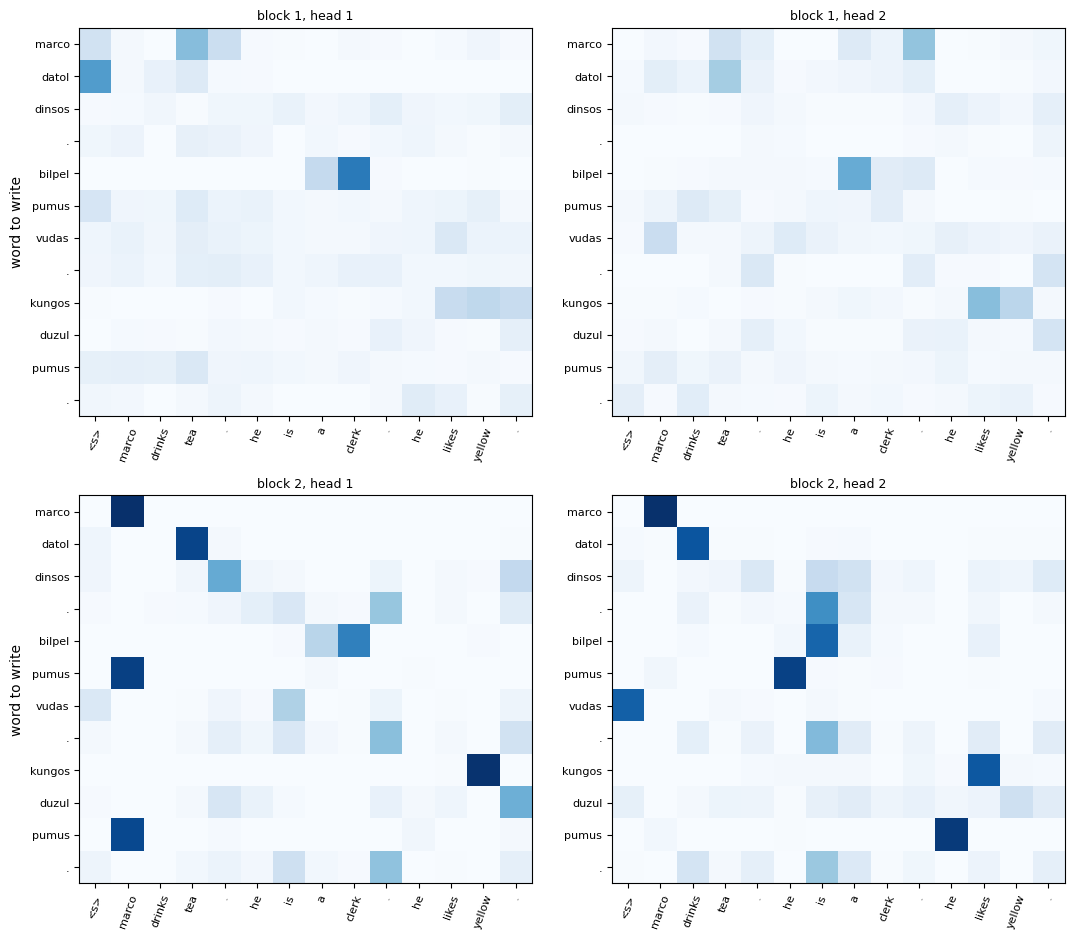

source: <s> marco drinks tea . he is a clerk . he likes yellow .
target: <s> marco datol dinsos . bilpel pumus vudas . kungos duzul pumus .


In [16]:
model = trained["20 worlds", 0]
source, target = TEST["new world"][0][:1], TEST["new world"][1][:1]

def cross_weights(model, source, target):
    with torch.no_grad():
        model(source, target[:, :-1], keep_weights=True)
    return [block.cross_attention.weights for block in model.decoder]            # (batch, heads, target positions, source positions)

weights = cross_weights(model, source, target)
source_words, target_words = vocab_a.decode(source[0].tolist()), vocab_b.decode(target[0].tolist())
n_sentences = 3
cut_s = [i for i, w in enumerate(source_words) if w == "."][n_sentences - 1] + 1
cut_t = [i for i, w in enumerate(target_words) if w == "."][n_sentences - 1]
fig, axes = plt.subplots(2, 2, figsize=(11, 9.5))
for layer in range(2):
    for head in range(2):
        ax = axes[layer, head]
        ax.imshow(weights[layer][0, head, :cut_t, :cut_s], cmap="Blues", vmin=0, vmax=1)
        ax.set_xticks(range(cut_s), source_words[:cut_s], rotation=70, fontsize=8)
        ax.set_yticks(range(cut_t), target_words[1:cut_t + 1], fontsize=8)
        ax.set_title(f"block {layer + 1}, head {head + 1}", fontsize=9)
axes[0, 0].set_ylabel("word to write"); axes[1, 0].set_ylabel("word to write")
plt.tight_layout()
plt.show()
print("source:", " ".join(source_words[:cut_s]))
print("target:", " ".join(target_words[:cut_t + 1]))

The figure can be read as a table: for each word to write, the word of the source that has the largest weight in the second block, for each head.

In [17]:
pd.DataFrame({f"head {head + 1}": [source_words[weights[1][0, head, j].argmax()] for j in range(cut_t)] for head in range(2)},
             index=pd.Index(target_words[1:cut_t + 1], name="word to write")).T

word to write,marco,datol,dinsos,.,bilpel,pumus,vudas,.,kungos,duzul,pumus,.
head 1,marco,tea,.,.,clerk,marco,is,.,yellow,.,marco,.
head 2,marco,drinks,is,is,is,he,<s>,is,likes,yellow,he,is


In the first block (above) the weights are spread: the cells are light and nothing is sharp. In the **second block** (below) many rows have one dark cell, and the table says where. **Head 1** reads the names and the values: `marco` from `marco`, `datol` (tea) from `tea`, `bilpel` (clerk) from `clerk`, `kungos` (yellow) from `yellow`; and to write the pronoun `pumus` it looks at the name `marco`, the person that `he` refers to. **Head 2** reads the names and the pronouns (`marco` from `marco`, `pumus` from `he`) and, for the other words of the sentence, the word that says the relation: `drinks`, `is`, `likes`. The two heads do not do the same thing. In the row of `vudas` (the verb of the job) head 2 puts its weight on `<s>`, and we did not look into why (it may be a head with nothing to read in that position). This is **one document** of the new world, taken as it is and not chosen: the next table measures a part of the same thing on 300 documents.

To measure what the figure shows we need to know, for each word of the target, which word of the source it translates. In our data it is known: the generator writes the two documents from the same facts, so each word of B comes from a word of A of the same sentence (the name from the name, the value of B from the value of A through the dictionary, the verb from the verb, the pronoun from the pronoun, `.` from `.`). For every position that has to write a word we add the weights that the head gives to the **corresponding word** of the source, and we average by kind of word, on 300 documents of the new world. A value of 1 would mean that the head looks only at the right word.

In [18]:
SOURCE_VALUES = {v for values in world.values.values() for v in values}

def sentence_ids(words):
    return np.cumsum([0] + [w == "." for w in words[:-1]])

def aligned_mass(model, source, target):
    # for each (block, head) and kind of word, the mean weight on the source words that the target word translates
    weights = cross_weights(model, source, target)
    rows = []
    for i in range(len(source)):
        s_words, t_words = vocab_a.decode(source[i].tolist()), vocab_b.decode(target[i].tolist())
        s_sentence, t_sentence = sentence_ids(s_words), sentence_ids(t_words)
        for j in range(1, len(t_words)):
            if t_words[j] == "<pad>":
                break
            if t_words[j] == "</s>":
                aligned = [k for k, w in enumerate(s_words) if w == "</s>"]
            else:
                aligned = [k for k, w in enumerate(s_words) if s_sentence[k] == t_sentence[j] and a2b.get(w) == t_words[j]]
            previous = kind_of(t_words[j - 1])
            value = [k for k, w in enumerate(s_words) if s_sentence[k] == t_sentence[j] and w in SOURCE_VALUES]       # the value word of the sentence
            for layer in range(len(weights)):
                for head in range(weights[layer].shape[1]):
                    w = weights[layer][i, head, j - 1]
                    rows.append((layer + 1, head + 1, kind_of(t_words[j]), previous, w[aligned].sum().item(), w[value].sum().item()))
    return pd.DataFrame(rows, columns=["block", "head", "kind", "previous", "mass", "mass on the value"])

mass = {seed: aligned_mass(trained["20 worlds", seed], TEST["new world"][0][:300], TEST["new world"][1][:300]) for seed in range(2)}
table = pd.concat({f"seed {seed}": m.pivot_table(index=["block", "head"], columns="kind", values="mass") for seed, m in mass.items()})
table[["name", "pronoun", "value", "verb", ".", "end"]].round(2)

kind               name  pronoun  value  verb     .   end
       block head                                        
seed 0 1     1     0.06     0.07   0.23  0.04  0.05  0.03
             2     0.08     0.07   0.14  0.05  0.11  0.01
       2     1     0.66     0.28   0.77  0.05  0.09  0.01
             2     0.89     0.94   0.27  0.22  0.05  0.03
seed 1 1     1     0.01     0.02   0.04  0.03  0.09  0.00
             2     0.06     0.19   0.09  0.07  0.11  0.01
       2     1     0.85     0.97   0.91  0.08  0.10  0.05
             2     0.19     0.56   0.46  0.01  0.15  0.02

The **first block** does not align: the weights on the corresponding words are between 0.00 and 0.23 in all the heads of the two seeds. The **second block** does, and the division of the work is not the same in the two seeds. In seed 0 head 1 reads the values (0.77) and the names (0.66) and head 2 the names (0.89) and the pronouns (0.94); in seed 1 head 1 alone reads the names (0.85), the pronouns (0.97) and the values (0.91), and head 2 does less (0.19, 0.56, 0.46). The network does not do what it does in one way only: the heads are interchangeable, and from one training to another the roles change. The full stops, the verbs and `</s>` have a low weight (0.01-0.22) in all the cases: the decoder does not need to look at the source to know where a sentence ends.

The verb deserves a closer look. In three of the four templates of language B the verb comes right after a word that already says the relation (after the value of a drink, of a job, of a colour); in the fourth (the city, `{subject} {verb} {value}`) it comes right after the name or the pronoun, and the only place where the relation can be read is the source. If the cross-attention is used only where it is needed, the weight on the verb should be higher in the second case. We separate the verbs by the kind of the previous word of the target.

In [19]:
verbs = pd.concat({f"seed {seed}": m[m["kind"] == "verb"].assign(previous=lambda d: d["previous"].replace({"pronoun": "name or pronoun", "name": "name or pronoun"}))
                  .pivot_table(index=["block", "head"], columns="previous", values=["mass", "mass on the value"]) for seed, m in mass.items()})
verbs.loc[(slice(None), 2), :].round(2).rename(columns={"mass": "weight on the verb of the source"})

weight on the verb of the source       mass on the value  \
previous                           name or pronoun value   name or pronoun   
       block head                                                            
seed 0 2     1                                0.08  0.03              0.04   
             2                                0.39  0.04              0.03   
seed 1 2     1                                0.07  0.10              0.03   
             2                                0.01  0.01              0.03   

                         
previous          value  
       block head        
seed 0 2     1     0.01  
             2     0.11  
seed 1 2     1     0.06  
             2     0.02

The idea that the verb is read from the source when it cannot be guessed is **not confirmed**. It is true in one head of one seed: seed 0, block 2, head 2 puts 0.39 of its weight on the verb of the source when the previous word is a name or a pronoun, and 0.04 when it is a value. But the other head of the same seed and both heads of seed 1 do not (0.08 against 0.03, 0.07 against 0.10, 0.01 against 0.01), and nobody reads the value of the sentence at that position (at most 0.11). So the relation reaches the position of the verb in another way, and we do not know which: it can be read earlier in the same sentence and carried forward by the self-attention of the decoder, which is where the decoder remembers what it has already written. We did not test it. The lesson of L1.0 applies again: the map says where a head looks, not where the information that the network uses comes from.

## Step 5: teacher forcing and decoding

> **A simple example.** To write `anna zuszu baris .` the decoder predicts `anna` after `<s>`, `zuszu` after `<s> anna`, `baris` after `<s> anna zuszu`. During training, at each position, the previous words are the **true** ones, the words of the data, and all the positions are trained together. When we translate a new sentence there are no true words: after `<s>` the decoder writes `anna`, and *this* is what it reads to write the following word, and so on. If at some point it writes a wrong word, the next positions will read it.
>
> The question of this section is: is the network the same when it reads its own words? The intuition is that an error could spread, because it enters the context of all the following positions.

The two situations have names. In training the decoder is fed with the true target (**teacher forcing**): the loss of a position is $-\log P(y_t \mid y_{<t}, s)$ with the **true** $y_{<t}$, so that all the positions can be computed in one pass and the training is fast. In use the decoder is fed with its own words: it must produce $\hat{y}_1$ from $\langle s\rangle$, then $\hat{y}_2$ from $\langle s\rangle, \hat{y}_1$, and so on, until it writes `</s>` (**autoregressive decoding**). The code is short. The source is encoded once; the decoder is run again at each word on the text written so far.

In [20]:
print(inspect.getsource(tinylm.translate))

def translate(model, source, max_length=32, bos=1, eos=2):
    # greedy autoregressive decoding of a batch of sources: the encoder runs once, the decoder one word at a time
    with torch.no_grad():
        memory, real = model.encode(source)
        out = torch.full((len(source), 1), bos)
        for _ in range(max_length - 1):
            word = model.decode(memory, real, out)[:, -1].argmax(dim=-1, keepdim=True)
            out = torch.cat([out, word], dim=1)
            if ((out == eos).any(dim=1)).all():
                break
    return out



We compare the two situations on the same network. A network trained to the end translates everything, and the two situations give the same result; to see a difference we need networks that are **not yet good**. We train the network of Step 3 (20 worlds, three seeds) for a small number of steps: 100, 200, 300 and 400. For each we measure the accuracy of the words under teacher forcing (the share of the words that are right when the prefix is true), the share of exact sentences that the decoding gives, and the share of exact sentences that we would expect **if the errors of the words were independent**, that is, the accuracy of the words raised to the power of the mean length of the target.

In [21]:
source_test, target_test = TEST["known world"]
mean_length = ((target_test[:, 1:] != 0).sum(1)).float().mean().item()

def teacher_forced_accuracy(model, source, target):
    with torch.no_grad():
        right = model(source, target[:, :-1]).argmax(-1) == target[:, 1:]
    real = target[:, 1:] != 0
    return (right & real).sum().item() / real.sum().item()

short = {}
rows = []
for steps in (100, 200, 300, 400):
    for seed in range(3):
        model = tinylm.fit_translation(*twenty, seed=seed, steps=steps)
        short[steps, seed] = model
        accuracy = teacher_forced_accuracy(model, source_test, target_test)
        exact, words = tinylm.translation_accuracy(model, source_test, target_test)
        rows.append({"steps": steps, "seed": seed, "words, true prefix": accuracy, "sentences expected if independent": accuracy ** mean_length,
                     "sentences, decoding": exact})
pd.DataFrame(rows).set_index(["steps", "seed"]).round(3)

words, true prefix  sentences expected if independent  \
steps seed                                                          
100   0                  0.626                              0.000   
      1                  0.595                              0.000   
      2                  0.617                              0.000   
200   0                  0.806                              0.005   
      1                  0.687                              0.000   
      2                  0.741                              0.001   
300   0                  0.984                              0.670   
      1                  0.885                              0.047   
      2                  0.864                              0.026   
400   0                  1.000                              0.999   
      1                  0.998                              0.963   
      2                  0.996                              0.894   

            sentences, decoding  
steps seed                       
100   0                   0.000  
      1                   0.000  
      2                   0.000  
200   0                   0.000  
      1                   0.000  
      2                   0.000  
300   0                   0.653  
      1                   0.012  
      2                   0.006  
400   0                   0.999  
      1                   0.962  
      2                   0.893

At 100 and 200 steps the network is not trained (60% to 81% of the words, no exact sentence). At 300 steps the three seeds are in three different states: 98.4%, 88.5% and 86.4% of the words with the true prefix, and 65.3%, 1.2% and 0.6% of the sentences with the decoding. At 400 steps all the seeds are above 99.6% of the words, and 89% to 99.9% of the sentences. This is the gap that the table wants to show: a network with **98.4% of the right words translates 65% of the sentences**, and one with 88.5% translates 1%, because a target has about 25 words and a sentence is exact only if all of them are right. The column of the expectation says it: 0.984 raised to the 25th is 0.67 and the decoding gives 0.653. In the two other seeds the expectation is a few percent (4.7% and 2.6%) and the decoding gives 1.2% and 0.6%: the same order of magnitude, the formula is a guide and not a law, because the words of a document are not independent.

Is it true that an error spreads? We measure it in two ways. First, after the **first error** of the decoding, we take the share of the following words that are right: if the error spreads, it must be lower than the share that the same network has at the same positions when the prefix is the true one. Second, on the network trained to the end, we put a **wrong word in the prefix**, at a random position, and we see which of the following predictions are damaged.

In [22]:
def after_first_error(model, source, target):
    out = tinylm.translate(model, source, max_length=target.shape[1])
    with torch.no_grad():
        right = model(source, target[:, :-1]).argmax(-1) == target[:, 1:]
    decoding, forced = [], []
    for i in range(len(target)):
        stop = (target[i] == 2).nonzero()[0].item() + 1
        if out.shape[1] < stop:
            continue
        wrong = (out[i, 1:stop] != target[i, 1:stop]).nonzero()
        if len(wrong) == 0:
            continue
        first = wrong[0].item()                                    # position of the first error among the words to write
        decoding += (out[i, 2 + first:stop] == target[i, 2 + first:stop]).tolist()
        forced += right[i, 1 + first:stop - 1].tolist()
    return np.mean(decoding), np.mean(forced), len(decoding)

for seed in range(3):
    d, f, n = after_first_error(short[300, seed], source_test, target_test)
    print(f"300 steps, seed {seed}: after the first error, words right with the decoding {d:.3f}, with the true prefix {f:.3f} ({n:,} words)")

300 steps, seed 0: after the first error, words right with the decoding 0.984, with the true prefix 0.990 (4,975 words)
300 steps, seed 1: after the first error, words right with the decoding 0.888, with the true prefix 0.901 (19,019 words)


300 steps, seed 2: after the first error, words right with the decoding 0.869, with the true prefix 0.874 (19,131 words)


In [23]:
def wrong_word_in_prefix(model, source, target, seed=0):
    generator = torch.Generator().manual_seed(seed)
    inputs = target[:, :-1].clone()
    length = (target != 0).sum(1) - 1                                  # number of words that the decoder reads, <s> included
    position = (torch.rand(len(inputs), generator=generator) * (length - 2)).long() + 1
    inputs[torch.arange(len(inputs)), position] = torch.randint(len(toyworld.SPECIALS), len(vocab_b), (len(inputs),), generator=generator)
    with torch.no_grad():
        right = (model(source, inputs).argmax(-1) == target[:, 1:]).tolist()
    groups = {"words before the wrong one": [], "word predicted from the wrong one": [], "rest of the same sentence": [], "following sentences": []}
    for i in range(len(inputs)):
        p, n = position[i].item(), length[i].item()
        end = next((j for j in range(p, n) if target[i, j + 1] == vocab_b.index["."]), n - 1)
        for j in range(n):
            key = ("words before the wrong one" if j < p else "word predicted from the wrong one" if j == p
                   else "rest of the same sentence" if j <= end else "following sentences")
            groups[key].append(right[i][j])
    return pd.Series({k: np.mean(v) for k, v in groups.items()}).round(3)

wrong_word_in_prefix(trained["20 worlds", 0], source_test, target_test)

words before the wrong one           1.000
word predicted from the wrong one    0.444
rest of the same sentence            1.000
following sentences                  1.000
dtype: float64

In our toy the idea that an error spreads is **not confirmed**. After the first error of the decoding, the share of the words that are right is 98.4%, 88.8% and 86.9% for the three seeds, against 99.0%, 90.1% and 87.4% that the same network has at the same positions with the true prefix: the difference is at most 1.3 points. And on the network trained to the end a wrong word in the prefix damages only the **next** word (right 44.4% of the times, the wrong word being the input from which it is predicted): the rest of the same sentence and the following sentences are right 100% of the times. A reasonable explanation is that in this task each word of the target depends mainly on the source, that the decoder reads again at each position, and little on the words written before; we did not test it with a task in which the target depends on itself. The gap of the previous table is therefore the product of many small errors, not the spread of one: the sentences fail because they are long, not because they get worse after the first mistake.

One failure, to see what a wrong translation looks like: the first document of the known world that the network of 300 steps and seed 0 does not translate exactly. The words that differ from the reference are between asterisks.

In [24]:
model = short[300, 0]
out = tinylm.translate(model, source_test, max_length=target_test.shape[1])
for i in range(len(source_test)):
    stop = (target_test[i] == 2).nonzero()[0].item() + 1
    if out.shape[1] < stop or not (out[i, :stop] == target_test[i, :stop]).all():
        reference = vocab_b.decode(target_test[i, :stop].tolist())
        written = vocab_b.decode(out[i, :stop].tolist())
        print("source:   ", " ".join(vocab_a.decode(source_test[i].tolist(), skip_special=True)))
        print("reference:", " ".join(reference[1:]))
        print("decoding: ", " ".join(w if w == r else f"*{w}*" for w, r in zip(written[1:], reference[1:])))
        break

source:    chiara lives in bari . chiara drinks cocoa . she is a farmer . diego lives in naples . he is a nurse . he drinks coffee .
reference: chiara zuszu polnen . chiara tavar dinsos . parpol lirnes vudas . diego zuszu tunrus . rerfur pumus vudas . pumus torge dinsos . </s>
decoding:  chiara zuszu polnen . chiara tavar dinsos . parpol lirnes vudas . diego zuszu tunrus . *vosgo* pumus vudas . pumus torge dinsos . </s>


The network wrote `vosgo` (*teacher*) in place of `rerfur` (*nurse*) in the sentence of the pronoun (`he is a nurse`), and all the other words are right, including the ones that follow. It is the typical error of a network that is not trained to the end: a value taken from the wrong place. **What changes with the real models.** In a long free generation (a story, an answer of several paragraphs) there is no source to look at again at each word, and what the model has written is the main part of its context: in that case the difference between the training with the true prefix and the use with its own words is known in the literature (the *exposure bias*, with remedies such as the *scheduled sampling* of Bengio et al., 2015, quoted from memory) and the toy of this notebook does not show it. We come back to the generation with the decoder alone in L1.4.

## Conclusions and what changes with the real models

We have built the second architecture of the course: **two stacks** (an encoder that reads the source and a decoder that writes the target) joined by the **cross-attention**, in which the queries come from the decoder and the keys and the values from the encoder. The ingredients are those of L1.1; what changes are the masks and the origin of the memory. In the toy world:

- the network translates from A to B with all the sentences exact (Step 3), but **only if the facts change from a document to another**: with a single world the same network writes the facts of the world in the places where it should read the source;
- without the cross-attention the decoder cannot translate, because it never sees the source;
- the cross-attention can be read as an alignment in the second block (Step 4): the heads send most of their weight to the source word that corresponds to the target word, for names, pronouns and values, in a division of the work that changes from one seed to another; the first block does not align, and where the verbs take the relation from is a question that we did not answer;
- the training with the true prefix and the decoding with the network's own words (Step 5) give a gap between the accuracy of the words and the accuracy of the sentences, that comes from the product of many small errors: in this toy an error of the decoding does not make the following words worse.

**What changes with the real models.** The original Transformer (Vaswani et al., 2017) is this model, with six blocks in the encoder and six in the decoder, vectors of 512 numbers and eight heads (from memory), trained on millions of pairs of sentences of two languages with a vocabulary of subwords (L0.1). Models of this family are still used (T5 and BART are encoder-decoder models, quoted from memory), but the most used large language models today have only the decoder: a single stack with the causal mask, in which the source and the target are a single text and the cross-attention is replaced by the ordinary self-attention (this is the subject of L1.4, where we also compare the two designs on this same translation). In a real translation the alignment is not a clean table: the same source word can be translated in different ways, words are missing or added, and the quality is measured with scores such as BLEU rather than with exact sentences. Our toy has no such problem: the translation is deterministic and each word of the target has a source. This is its advantage (we can read the alignment and know the right answer) and its limit (we see nothing of what makes a real translation hard).

The next notebook uses the encoder alone. In our network each position of the source reads all the others, on its left and on its right; if we take this stack and train it to **fill the words that we hide** in a text, instead of writing a target, we get BERT.